# Part 2: The 561 features, how they overlap, and PCA

**Data used:** the 21 training people only (`train/`). The 9 test people are untouched.
This part mostly *looks* at the features. The only model (Cell 10) is scored with the saved person-wise folds.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import PredefinedSplit, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from config import SEED, DATA

X = pd.read_csv(DATA + "/train/X_train.txt", sep=r"\s+", header=None).values
y = np.loadtxt(DATA + "/train/y_train.txt", dtype=int)
groups = np.loadtxt(DATA + "/train/subject_train.txt", dtype=int)
names = pd.read_csv(DATA + "/features.txt", sep=r"\s+", header=None)[1].values
activity = {1: "walking", 2: "upstairs", 3: "downstairs", 4: "sitting", 5: "standing", 6: "lying"}

folds_table = pd.read_csv("results/folds.csv", index_col="person")["fold"]
fold_of_window = folds_table.loc[groups].values
saved_folds = PredefinedSplit(fold_of_window)

print(X.shape, len(names), "feature names,", len(set(names)), "unique")

(7352, 561) 561 feature names, 477 unique


## What the 561 features are
Each feature is **one number computed from one 2.56 s window**. Its name says how it was made, e.g. `tBodyAcc-mean()-X`:
- **t / f:** computed on the signal over **time**, or on its **frequency** spectrum (FFT). `angle(...)` features are angles between average directions.
- **Body / Gravity:** the fast body-motion part or the slow gravity part of the acceleration (split with a 0.3 Hz filter, Part 1).
- **Acc / Gyro:** accelerometer or gyroscope.
- **Jerk:** the rate of change of the signal (how sudden the motion is). **Mag:** the size of the 3-D vector, √(x² + y² + z²), which does not depend on how the phone is turned.
- **The statistic:** `mean()`, `std()`, `mad()` (median absolute deviation), `max()`, `min()`, `energy()`, `entropy()`, `bandsEnergy()` (energy in a frequency band), and so on.
- **-X / -Y / -Z:** the axis.

In [2]:
feature_table = pd.DataFrame({"name": names})
feature_table["domain"] = np.where(feature_table["name"].str.startswith("angle"), "angle",
                          np.where(feature_table["name"].str.startswith("t"), "time", "frequency"))
feature_table["part"] = np.where(feature_table["name"].str.contains("Gravity"), "Gravity", "Body")
feature_table["sensor"] = np.where(feature_table["name"].str.contains("Gyro"), "Gyro", "Acc")
feature_table["jerk"] = feature_table["name"].str.contains("Jerk")
feature_table["magnitude"] = feature_table["name"].str.contains("Mag")
feature_table["statistic"] = feature_table["name"].str.extract(r"-([A-Za-z]+)")[0].fillna("angle")

print(feature_table["domain"].value_counts().to_string(), "\n")
print(pd.crosstab(feature_table["sensor"], feature_table["part"]).to_string(), "\n")
print("Jerk features:", feature_table["jerk"].sum(), "| Magnitude features:", feature_table["magnitude"].sum(), "\n")
print(feature_table["statistic"].value_counts().to_string())

domain
frequency    289
time         265
angle          7 

part    Body  Gravity
sensor               
Acc      295       53
Gyro     213        0 

Jerk features: 213 | Magnitude features: 117 

statistic
bandsEnergy    126
arCoeff         80
mean            33
std             33
mad             33
energy          33
iqr             33
max             33
min             33
entropy         33
sma             17
correlation     15
maxInds         13
meanFreq        13
skewness        13
kurtosis        13
angle            7


## How much do the features overlap?
We compute the correlation **r** between every pair of features over all training windows. |r| close to 1 means two features rise and fall together, so they carry nearly the same information. 561 features give 561 × 560 / 2 = 157,080 pairs.

(This only *describes* the data; no model learns from it, so it does not need the person-wise folds.)

In [3]:
corr = np.corrcoef(X, rowvar=False)
upper = np.triu_indices_from(corr, k=1)
abs_r = np.abs(corr[upper])

print("pairs:", len(abs_r))
for limit in [0.9, 0.95, 0.99]:
    print(f"pairs with |r| > {limit}:", (abs_r > limit).sum())

has_copy = (np.abs(corr) - np.eye(561) > 0.9).any(axis=1)
print("features with at least one near-copy (|r| > 0.9):", has_copy.sum(), "of 561")

order = np.argsort(-abs_r)[:8]
print()
print("most similar pairs:")
for k in order:
    i, j = upper[0][k], upper[1][k]
    print(f"  r = {corr[i, j]:.4f}   {names[i]}  vs  {names[j]}")

pairs: 157080
pairs with |r| > 0.9: 8206
pairs with |r| > 0.95: 2281
pairs with |r| > 0.99: 207
features with at least one near-copy (|r| > 0.9): 431 of 561

most similar pairs:
  r = 1.0000   tBodyAccJerkMag-mean()  vs  tBodyAccJerkMag-sma()
  r = 1.0000   tBodyAccMag-std()  vs  tGravityAccMag-std()
  r = 1.0000   tBodyAccMag-max()  vs  tGravityAccMag-max()
  r = 1.0000   tBodyGyroMag-mean()  vs  tBodyGyroMag-sma()
  r = 1.0000   fBodyBodyAccJerkMag-mean()  vs  fBodyBodyAccJerkMag-sma()
  r = 1.0000   tBodyAccMag-energy()  vs  tGravityAccMag-energy()
  r = 1.0000   tBodyAccMag-mad()  vs  tGravityAccMag-mad()
  r = 1.0000   fBodyBodyGyroMag-mean()  vs  fBodyBodyGyroMag-sma()


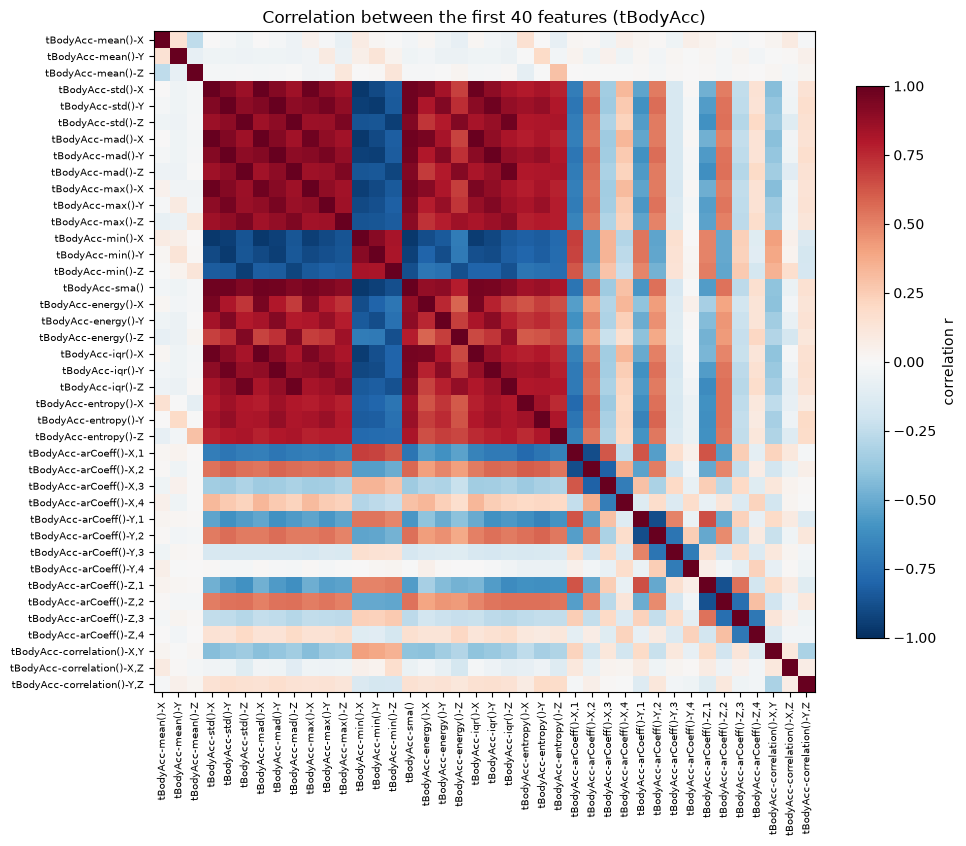

std/mad/max/min features (columns 3-17): mean |r| between them = 0.881


In [4]:
# A readable subset: the first 40 features, all from tBodyAcc (body acceleration, time domain)
subset = list(range(40))

plt.figure(figsize=(10, 8.5))
plt.imshow(corr[np.ix_(subset, subset)], cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(label="correlation r", shrink=0.8)
plt.xticks(range(40), names[subset], rotation=90, fontsize=7)
plt.yticks(range(40), names[subset], fontsize=7)
plt.title("Correlation between the first 40 features (tBodyAcc)")
plt.tight_layout()
plt.show()

block = np.abs(corr[np.ix_(range(3, 18), range(3, 18))])
print("std/mad/max/min features (columns 3-17): mean |r| between them =", round(block[np.triu_indices(15, 1)].mean(), 3))

## Why this matters for Parts 4 and 6
- **Lasso (Part 4)** keeps one feature from a group of near-copies and sets the rest to zero. When copies are almost identical, *which* one it keeps depends on small details of the training people, so the chosen list changes from fold to fold. The *number* of features it needs is stable; the *names* are not.
- **Random forest (Part 6)** spreads its splits over the copies, so each copy gets only part of the importance. Shuffling one copy barely hurts, because the forest can use another (in Part 6: 0.0004 for one gravity feature alone vs 0.196 for its group of 5).
- So with this data, importance belongs to **groups of related features**, not to single columns.

## PCA: summarising the 561 features with fewer numbers
**PCA** (principal component analysis) finds new axes, called **components**, that are weighted mixes of all 561 features:
- Component 1 is the direction in which the windows **vary the most**, component 2 the direction of most remaining variation at right angles to the first, and so on.
- Because many features are near-copies, a few components can hold most of the variation.
- We **standardise first** (each feature mean 0, std 1), so no feature dominates just because of its range. Scaler and PCA go in one `make_pipeline`, so when PCA feeds a model (Cell 10), it is fitted on each fold's training people only.
- The plots below fit PCA on all 21 training people at once. That is fine for *looking*, because no score is computed from them.

components for 90% of the variance: 63
components for 95% of the variance: 102
components for 99% of the variance: 179
variance held by PC1: 0.508 | PC2: 0.066 | first 10 together: 0.708


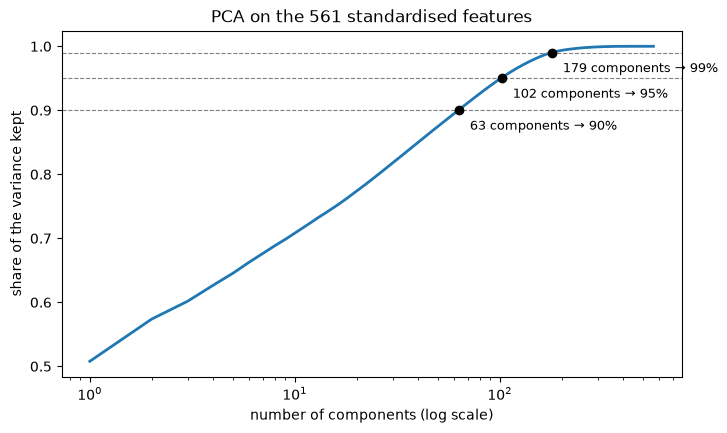

In [5]:
pca_pipe = make_pipeline(StandardScaler(), PCA(random_state=SEED))
Z = pca_pipe.fit_transform(X)
pca = pca_pipe[-1]
cumulative = np.cumsum(pca.explained_variance_ratio_)

needed = {}
for level in [0.90, 0.95, 0.99]:
    needed[level] = int(np.searchsorted(cumulative, level) + 1)
    print(f"components for {level:.0%} of the variance: {needed[level]}")
print("variance held by PC1:", round(pca.explained_variance_ratio_[0], 3), "| PC2:", round(pca.explained_variance_ratio_[1], 3),
      "| first 10 together:", round(cumulative[9], 3))

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, 562), cumulative, linewidth=2)
for level, k in needed.items():
    plt.axhline(level, color="grey", linestyle="--", linewidth=0.8)
    plt.plot(k, level, "o", color="black")
    plt.annotate(f"{k} components → {level:.0%}", (k, level), xytext=(8, -14), textcoords="offset points", fontsize=9)
plt.xscale("log")
plt.xlabel("number of components (log scale)")
plt.ylabel("share of the variance kept")
plt.title("PCA on the 561 standardised features")
plt.show()

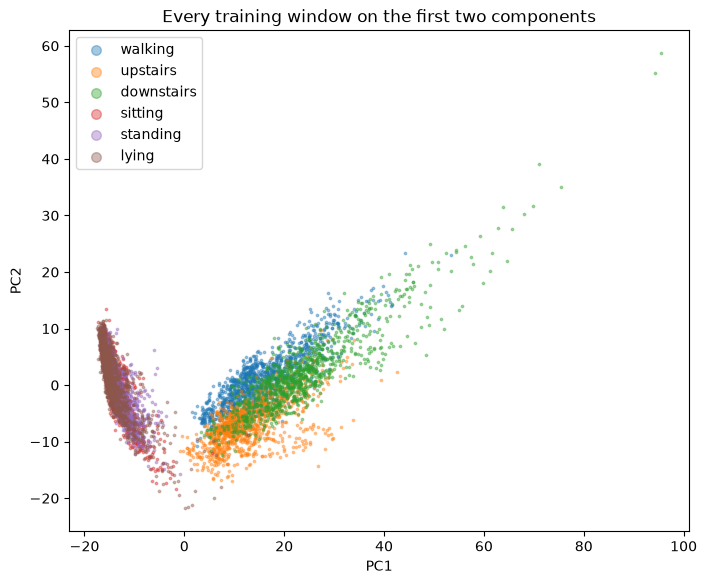

             PC1        PC2     
            mean   std mean  std
activity                        
standing   -13.5   2.4  0.2  4.6
sitting    -14.0   2.5  1.0  5.3
lying      -14.3   3.2  1.7  5.6
walking     15.8   7.4  1.0  4.9
downstairs  23.8  10.9  2.1  7.3
upstairs    12.9   6.5 -6.9  4.1


In [6]:
plt.figure(figsize=(8, 6.5))
for k, label in activity.items():
    mask = y == k
    plt.scatter(Z[mask, 0], Z[mask, 1], s=3, alpha=0.4, label=label)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(markerscale=4)
plt.title("Every training window on the first two components")
plt.show()

centres = pd.DataFrame({"PC1": Z[:, 0], "PC2": Z[:, 1], "activity": [activity[k] for k in y]})
print(centres.groupby("activity", sort=False)[["PC1", "PC2"]].agg(["mean", "std"]).round(1).to_string())

In [7]:
for pc in [0, 1]:
    weights = pca.components_[pc]
    top = np.argsort(-np.abs(weights))[:6]
    print(f"PC{pc + 1}: largest weights")
    for i in top:
        print(f"   {weights[i]:+.3f}  {names[i]}")
    print()

# What kind of features does each component lean on? (share of the squared weights)
for pc in [0, 1]:
    share = pd.Series(pca.components_[pc] ** 2).groupby(feature_table["part"] + " " + feature_table["sensor"]).sum()
    print(f"PC{pc + 1} weight share:", share.round(2).to_dict())

PC1: largest weights
   +0.059  fBodyAcc-sma()
   +0.059  fBodyAccJerk-sma()
   +0.059  tBodyAccJerk-sma()
   +0.059  fBodyGyro-sma()
   +0.058  tBodyAccJerkMag-mean()
   +0.058  tBodyAccJerkMag-sma()

PC2: largest weights
   +0.122  fBodyAcc-meanFreq()-Z
   +0.120  tBodyGyroMag-arCoeff()1
   +0.118  tBodyAccMag-arCoeff()1
   +0.118  tGravityAccMag-arCoeff()1
   +0.118  fBodyAccMag-meanFreq()
   +0.118  tGravityAcc-arCoeff()-Z,1

PC1 weight share: {'Body Acc': 0.59, 'Body Gyro': 0.37, 'Gravity Acc': 0.04}
PC2 weight share: {'Body Acc': 0.44, 'Body Gyro': 0.35, 'Gravity Acc': 0.21}


PC1: lying vs sitting/standing separation = 0.18
PC2: lying vs sitting/standing separation = 0.21
PC3: lying vs sitting/standing separation = 1.27
PC4: lying vs sitting/standing separation = 2.82
PC5: lying vs sitting/standing separation = 2.87
PC6: lying vs sitting/standing separation = 0.35


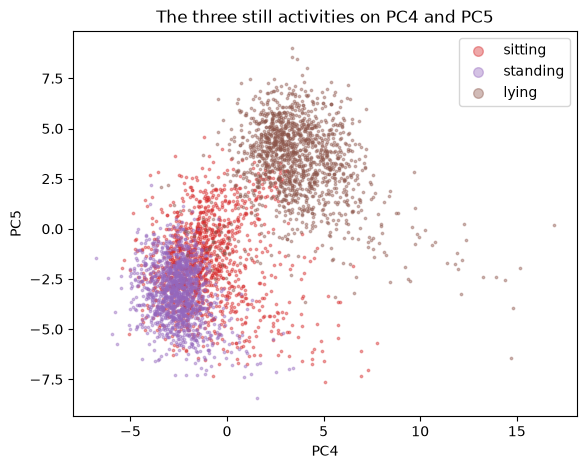

PC4 weight share: {'Body Acc': 0.44, 'Body Gyro': 0.27, 'Gravity Acc': 0.29}
PC5 weight share: {'Body Acc': 0.39, 'Body Gyro': 0.23, 'Gravity Acc': 0.38}


In [8]:
# Lying overlaps sitting and standing on PC1/PC2. Which component separates it?
# Separation = distance between the two group means, in units of their spread (like a z-score).
still = np.isin(y, [4, 5, 6])
lying = y == 6
for pc in range(6):
    a, b = Z[lying, pc], Z[still & ~lying, pc]
    separation = abs(a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
    print(f"PC{pc + 1}: lying vs sitting/standing separation = {separation:.2f}")

plt.figure(figsize=(6.5, 5))
for k in [4, 5, 6]:
    mask = y == k
    plt.scatter(Z[mask, 3], Z[mask, 4], s=3, alpha=0.4, label=activity[k], color=f"C{k - 1}")
plt.xlabel("PC4")
plt.ylabel("PC5")
plt.legend(markerscale=4)
plt.title("The three still activities on PC4 and PC5")
plt.show()

for pc in [3, 4]:
    share = pd.Series(pca.components_[pc] ** 2).groupby(feature_table["part"] + " " + feature_table["sensor"]).sum()
    print(f"PC{pc + 1} weight share:", share.round(2).to_dict())

## Does a model need all 561 features? Logistic regression on k components
Pipeline: `StandardScaler → PCA(k) → LogisticRegression` (default C = 1, as in Part 4), scored with the saved folds. The scaler and PCA are refitted on each fold's 18 training people. Runs in under a minute.

In [9]:
rows = []
for k in [10, 50, 100]:
    model = make_pipeline(StandardScaler(), PCA(n_components=k, random_state=SEED),
                          LogisticRegression(max_iter=2000))
    f1s = cross_val_score(model, X, y, cv=saved_folds, scoring="f1_macro", n_jobs=-1)
    rows.append({"features": f"{k} PCA components", "mean": f1s.mean(), "std": f1s.std(ddof=1)})

full = pd.read_csv("results/cv_logistic.csv")
full = full[(full["model"] == "logistic_L2") & (full["setting"] == "C=1")]["macro_f1"]
rows.append({"features": "all 561 features (Part 4)", "mean": full.mean(), "std": full.std()})
print(pd.DataFrame(rows).round(3).to_string(index=False))

                 features  mean   std
        10 PCA components 0.838 0.044
        50 PCA components 0.895 0.036
       100 PCA components 0.920 0.038
all 561 features (Part 4) 0.933 0.036


# Part 2 summary: the features, their overlap, and PCA

**Data used:** the 21 training people only. Nothing from the 9 test people.

## Cell by cell
**Cell 1: load.** X (7352 × 561), y, groups, the saved folds, and the feature names. Only **477 of the 561 names are unique**: some `bandsEnergy()` names repeat (one copy per axis, but the axis is missing from the name), so always refer to features by column number too.

**Cell 2: what kinds of features there are.**

| Group | Count |
|---|---|
| time domain / frequency domain / angle | 265 / 289 / 7 |
| Body acc / Gravity acc / Body gyro | 295 / 53 / 213 |
| Jerk features / Magnitude features | 213 / 117 |
| Most common statistics | bandsEnergy 126, arCoeff 80, then mean, std, mad, max, min, energy, iqr, entropy 33 each |

- Only 53 features describe **gravity** (the orientation of the phone), and 7 more are angles to gravity. The other ~500 describe **movement**.
- Most features come in families: the same statistic on X, Y, Z, on body/gravity, on time/frequency. That alone makes them overlap.

**Cells 3–4: correlation.** Of the 157,080 feature pairs:

| \|r\| above | 0.9 | 0.95 | 0.99 |
|---|---|---|---|
| pairs | **8,206** | 2,281 | 207 |

- **431 of the 561 features** have at least one near-copy (|r| > 0.9).
- Exact copies (r = 1.0000): `tBodyAccJerkMag-mean()` and `tBodyAccJerkMag-sma()`. A magnitude is never negative, so its "sum of absolute values" (sma) is just its mean. Also `tBodyAccMag-std()` and `tGravityAccMag-std()` (and their max, mad, energy): the "body" and "gravity" magnitude features are identical in this dataset, so they carry the same information twice.
- Heatmap (first 40 features, all `tBodyAcc`): the std, mad, max, min, energy, iqr and entropy features form one big dark block. They all measure **"how much is the body moving"** (mean |r| = 0.881 among std/mad/max/min). The three `mean()` features are almost uncorrelated with the rest: the mean of body acceleration is close to 0 by construction.

**Why it matters (Parts 4 and 6):** with near-copies, *which* copy a model uses is close to arbitrary. That is why **lasso's chosen features changed from fold to fold** (Part 4), and why the **random forest's importance is split** over copies (Part 6: shuffling one gravity feature costs 0.0004 macro-F1, shuffling its group of 5 costs 0.196). Importance belongs to groups, not single columns.

**Cell 5: PCA, how many components?** (scaler + PCA in one pipeline)
- **PC1 alone holds 50.8%** of the variance; PC2 only 6.6%; the first 10 together 70.8%.
- **63 components → 90%, 102 → 95%, 179 → 99%.** So the 561 features behave like roughly 100 independent numbers: another sign of strong overlap.

**Cells 6–8: what the components capture.**
- **PC1 = "how much is the person moving".** Its largest weights are all `sma()` (overall size) features of body acceleration, jerk and gyroscope; 96% of its weight is on body-motion features. On PC1, the still activities sit at about −14 and the moving ones at +13 to +24: **moving vs still separates almost completely** (a clear gap in the scatter, with only a few windows near 0).
- **Among the walking types**, upstairs is lower on PC2 (mean −6.9 vs about +1 to +2 for the others), and downstairs reaches further right on PC1 (stronger impacts). But the three clouds **overlap a lot**.
- **Sitting, standing and lying all sit on top of each other on PC1 and PC2.** PC1/PC2 hardly look at gravity (only 4% of PC1's weight).
- **Lying separates on PC4 and PC5** (separation 2.8–2.9 standard deviations, vs 0.2 on PC1/PC2); these components carry about 30–40% of their weight on gravity features. **Sitting vs standing still overlaps** there: the small hip tilt from Part 1 is not a big source of variation, so PCA does not give it its own direction.
- Lesson: PCA finds the directions with the **most variation**, not the ones that **separate the activities best**. Here the biggest variation (movement intensity) happens to be useful, but the posture information sits in later components.

**Cell 9: logistic regression on k components** (scaler + PCA + logistic regression in one pipeline, C = 1, saved folds).

| Inputs | macro-F1 (mean ± std) |
|---|---|
| 10 components | 0.838 ± 0.044 |
| 50 components | 0.895 ± 0.036 |
| 100 components | 0.920 ± 0.038 |
| all 561 features (Part 4) | 0.933 ± 0.036 |

- Fewer inputs cost accuracy: even 100 components (95% of the variance) lose about 0.013. The last few percent of variance still holds information the model uses, for example the small posture differences between sitting and standing.
- So PCA is useful for **understanding and plotting** the data, but we do **not** use it in front of our models. Lasso (Part 4) is a better way to use fewer features: about 180 original features with no loss.

## Five takeaways
1. The 561 features are **families** of the same few ideas: movement size, rhythm and frequency, orientation (gravity), on 3 axes and 2 sensors.
2. They **overlap heavily**: 8,206 pairs with |r| > 0.9, 431 features with a near-copy, some exact duplicates. About 100 components hold 95% of the variance.
3. Because of the overlap, **single-feature importance is unreliable** (lasso's unstable choices, the forest's split importance). Talk about groups of features.
4. **PC1 = movement intensity**: it alone almost separates moving from still. Lying appears on PC4/PC5 (gravity). Sitting vs standing and the three walking types overlap on the top components.
5. PCA keeps the **largest variation**, not the most **useful** variation: logistic regression on 100 components (0.920) is below all 561 features (0.933).